# ==============================================
## 1. Introduction & Background
## This code supports the research on crude oil price forecasting using multivariate time series models.
## It handles historical oil price and macroeconomic data and prepares it for use in VARMAX, XGBoost, and LSTM models.
# ==============================================


In [1]:
# *Meta information and documentation block describing the scope and purpose of the script.*

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Time series analysis and modeling imports
from statsmodels.tsa.seasonal import STL                    # Seasonal-Trend decomposition using LOESS
from statsmodels.tsa.stattools import adfuller              # Augmented Dickey-Fuller test for stationarity
from statsmodels.tsa.vector_ar.vecm import coint_johansen   # Johansen cointegration test
from statsmodels.stats.stattools import durbin_watson       # Test for autocorrelation in residuals
from statsmodels.tsa.api import VAR                         # Vector Autoregression model
from statsmodels.tsa.statespace.varmax import VARMAX        # VARMAX model for multivariate forecasting

# Evaluation and preprocessing
from sklearn.metrics import mean_squared_error, mean_absolute_error  # Error metrics
from sklearn.preprocessing import MinMaxScaler                       # Feature scaling

# Statistical diagnostics
from scipy.stats import shapiro                # Shapiro-Wilk test for normality
from scipy.stats.mstats import winsorize       # Winsorization to limit extreme values (outliers)

# Machine learning models
from xgboost import XGBRegressor               # XGBoost regression model

# Deep learning model (LSTM)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

import statsmodels.api as sm                                # General statsmodels access
from statsmodels.stats.diagnostic import het_breuschpagan   # Heteroskedasticity test
import shap                                                 # SHAP for model interpretability
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  # ACF and PACF plotting

# Ensure directories for saving plots and tables exist
# Automatically create output folders if they do not exist — ensures code doesn't break during file saving.
import os
os.makedirs("plots", exist_ok=True)
os.makedirs("tables", exist_ok=True)

2025-05-28 12:35:37.243497: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1748417737.254687   29293 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1748417737.258288   29293 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1748417737.268003   29293 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1748417737.268013   29293 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1748417737.268015   29293 computation_placer.cc:177] computation placer alr

In [2]:
# Load the Excel file containing historical monthly data
file_path = "CMO-Historical-Data-Monthly.xlsx"
xls = pd.ExcelFile(file_path, engine='openpyxl')  # Open the Excel workbook
monthly_prices_df = pd.read_excel(xls, sheet_name='Monthly Prices', skiprows=4, header=[0,1])

In [3]:
# Specify relevant columns of interest (multi-index columns with units)
selected_columns = [
    ('Crude oil, Brent', '($/bbl)'),
    ('Crude oil, WTI', '($/bbl)'),
    ('Coal, Australian', '($/mt)'),
    ('Coal, South African **', '($/mt)'),
    ('Natural gas, US', '($/mmbtu)'),
    ('Natural gas, Europe', '($/mmbtu)'),
    ('Liquefied natural gas, Japan', '($/mmbtu)'),
    ('Palm oil', '($/mt)'),
    ('Copper', '($/mt)'),
    ('Gold', '($/troy oz)')
]

In [4]:
# Extract and clean the selected data
df_selected = monthly_prices_df[selected_columns].copy()

# Flatten multi-level column names to single-level by joining names and units
df_selected.columns = [' '.join(col).strip() for col in df_selected.columns]

# Extract date from original multi-index columns and set as datetime index
df_selected['Date'] = pd.to_datetime(monthly_prices_df[('Unnamed: 0_level_0', 'Unnamed: 0_level_1')], format='%YM%m')
df_selected.set_index('Date', inplace=True)


# Convert all columns with object dtype to numeric, coercing errors to NaN
for col in df_selected.select_dtypes(include='object').columns:
    df_selected[col] = pd.to_numeric(df_selected[col], errors='coerce')


# ==============================================
## 6. Descriptive Analysis
# ==============================================

This Section heading for Exploratory Data Analysis (EDA) summarizes and visualizes the dataset before modeling.

In [5]:
# Compute descriptive statistics for each column

summary_stats = df_selected.describe().T  # Transpose for better formatting (variables as rows)
summary_stats['skewness'] = df_selected.skew()       # Add skewness column to capture data asymmetry
summary_stats['kurtosis'] = df_selected.kurtosis()   # Add kurtosis column to detect heavy/light tails
summary_stats.to_csv("tables/summary_stats.csv")     # Save stats to CSV for reporting

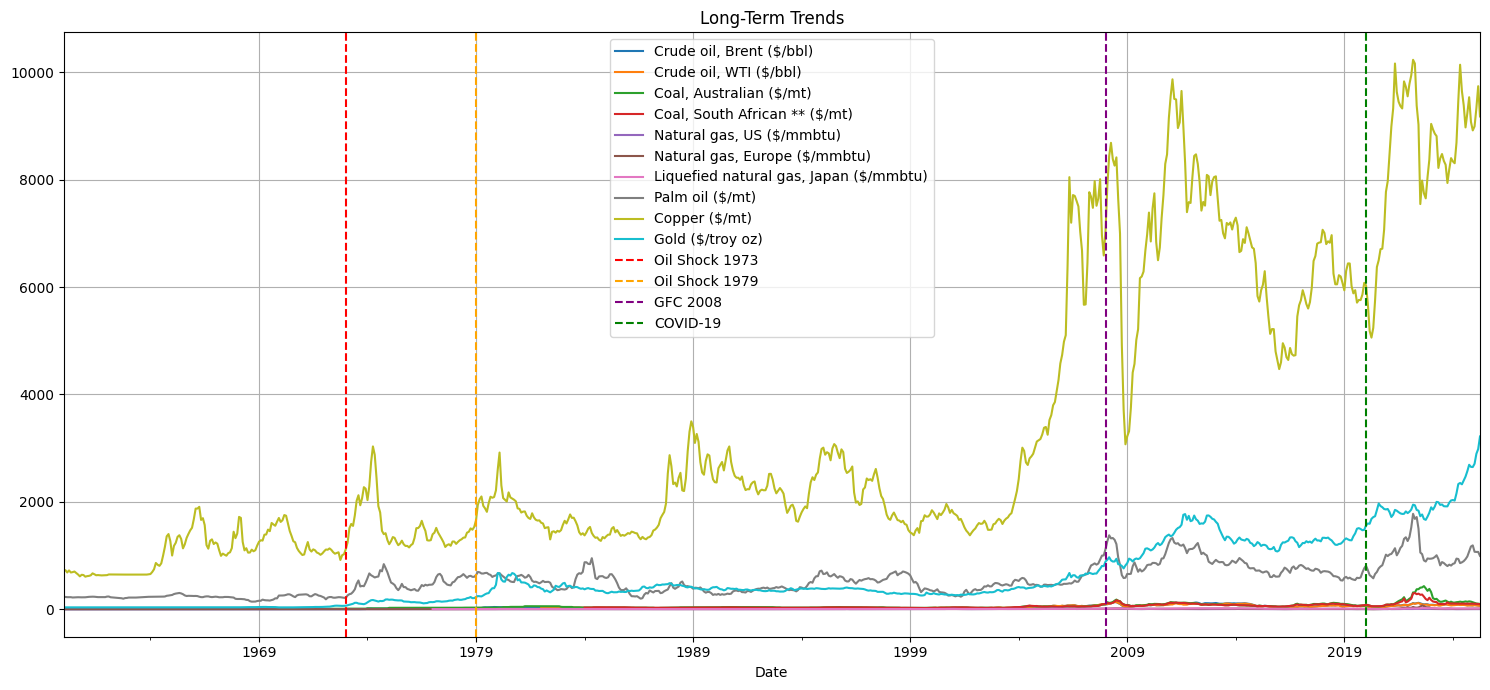

In [6]:
# This block generates and stores statistical summaries including mean, std, min, max, skewness, and kurtosis.*
# Plot long-term trends of selected commodity prices with major economic events annotated

plt.figure(figsize=(15, 7))
df_selected.plot(ax=plt.gca())  # Overlay all time series on one plot
plt.axvline(pd.to_datetime('1973-01-01'), color='red', linestyle='--', label='Oil Shock 1973')
plt.axvline(pd.to_datetime('1979-01-01'), color='orange', linestyle='--', label='Oil Shock 1979')
plt.axvline(pd.to_datetime('2008-01-01'), color='purple', linestyle='--', label='GFC 2008')
plt.axvline(pd.to_datetime('2020-01-01'), color='green', linestyle='--', label='COVID-19')
plt.title("Long-Term Trends"); plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig("plots/long_term_trends.png"); plt.show()

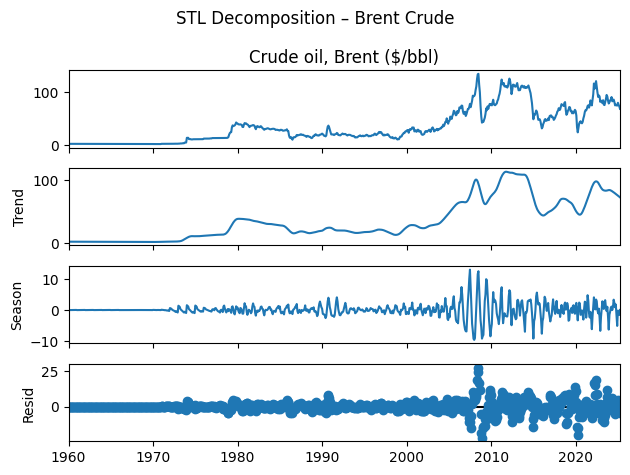

In [ ]:
# Perform Seasonal-Trend decomposition using LOESS (STL) for Brent crude
stl = STL(df_selected['Crude oil, Brent ($/bbl)'].dropna(), period=12)  # 12-month seasonality
stl.fit().plot(); plt.suptitle('STL Decomposition: Brent Crude')
plt.tight_layout()
plt.savefig("plots/stl_decomposition_brent.png"); plt.show()

<Figure size 1500x700 with 0 Axes>

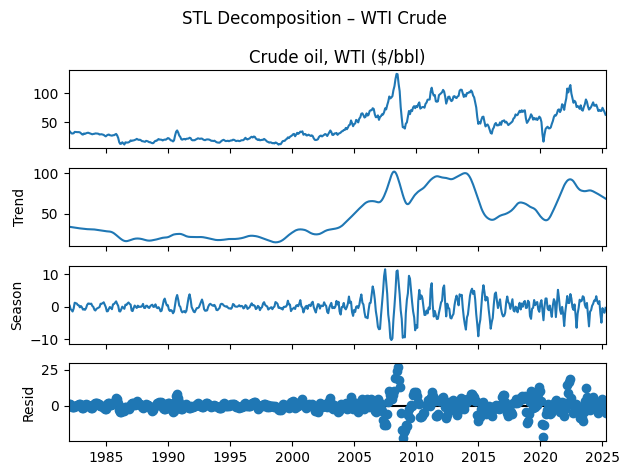

In [ ]:
# Apply STL decomposition with 12-month seasonality
stl_wti = STL(df_selected['Crude oil, WTI ($/bbl)'].dropna(), period=12)

# Plot and save the decomposition results
plt.figure(figsize=(15, 7))
stl_wti.fit().plot()
plt.suptitle('STL Decomposition: WTI Crude')
plt.tight_layout()
plt.savefig("plots/stl_decomposition_wti.png")
plt.show()

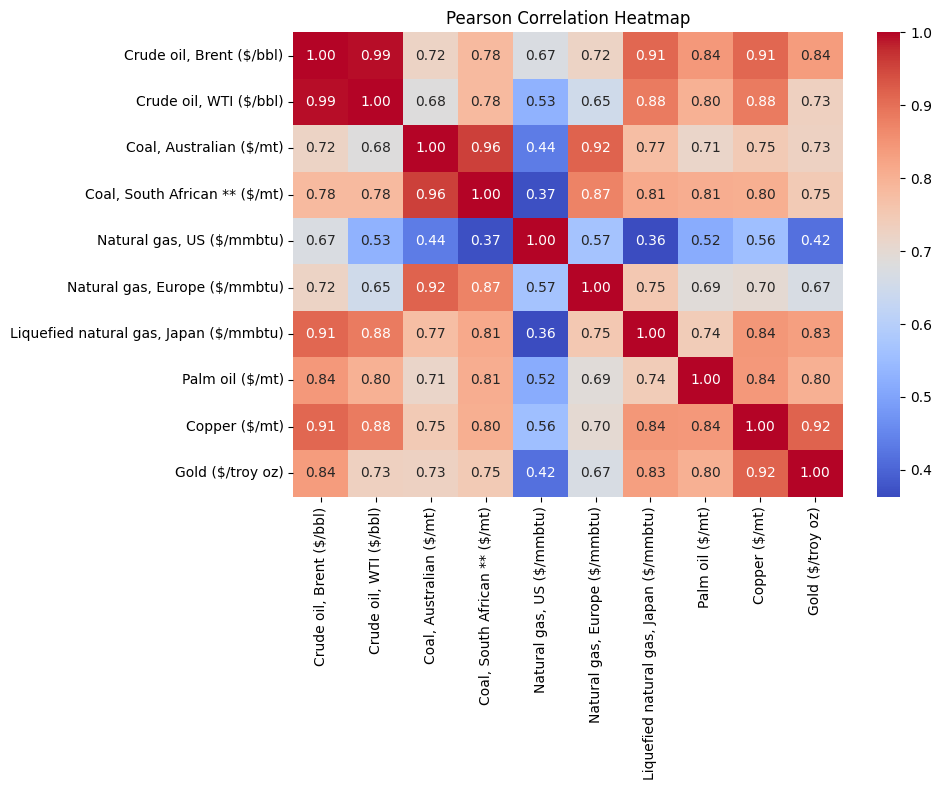

In [9]:
# Pearson correlation heatmap (linear relationships)
plt.figure(figsize=(10, 8))
sns.heatmap(df_selected.corr(method='pearson'), cmap="coolwarm", annot=True, fmt=".2f")
plt.title("Pearson Correlation Heatmap")
plt.tight_layout(); plt.savefig("plots/correlation_heatmap_pearson.png"); plt.show()

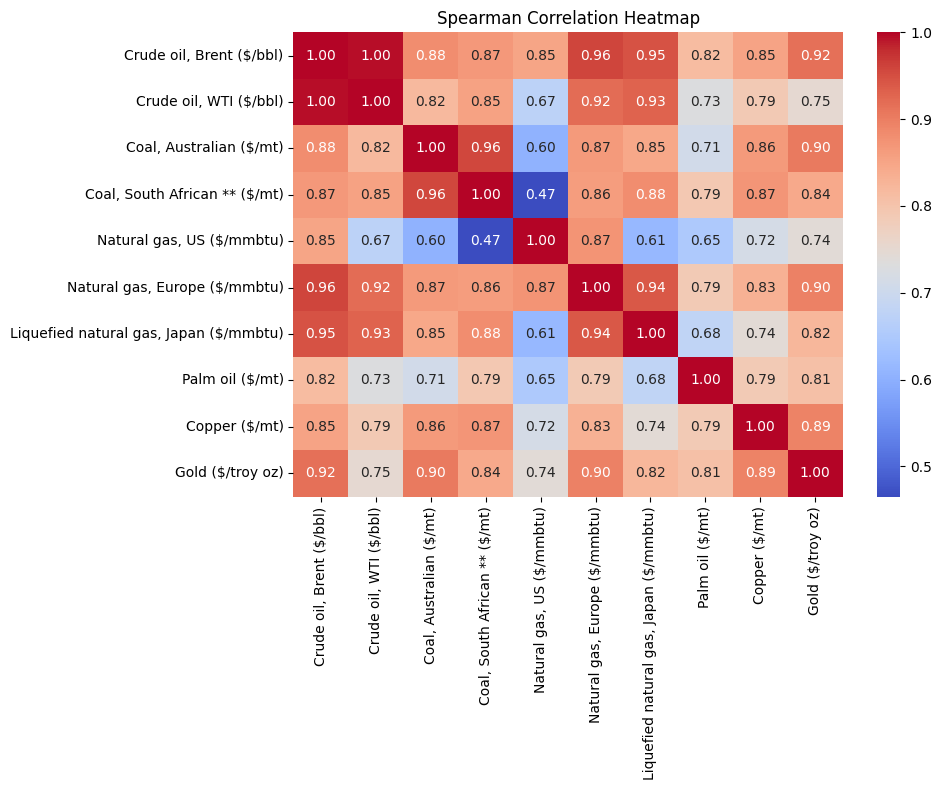

In [10]:
# Spearman correlation heatmap (monotonic relationships)
# Useful when the relationship between variables is not strictly linear but still ordered (monotonic)
plt.figure(figsize=(10, 8))
sns.heatmap(df_selected.corr(method='spearman'), cmap="coolwarm", annot=True, fmt=".2f")
plt.title("Spearman Correlation Heatmap")
plt.tight_layout(); plt.savefig("plots/correlation_heatmap_Spearman.png"); plt.show()

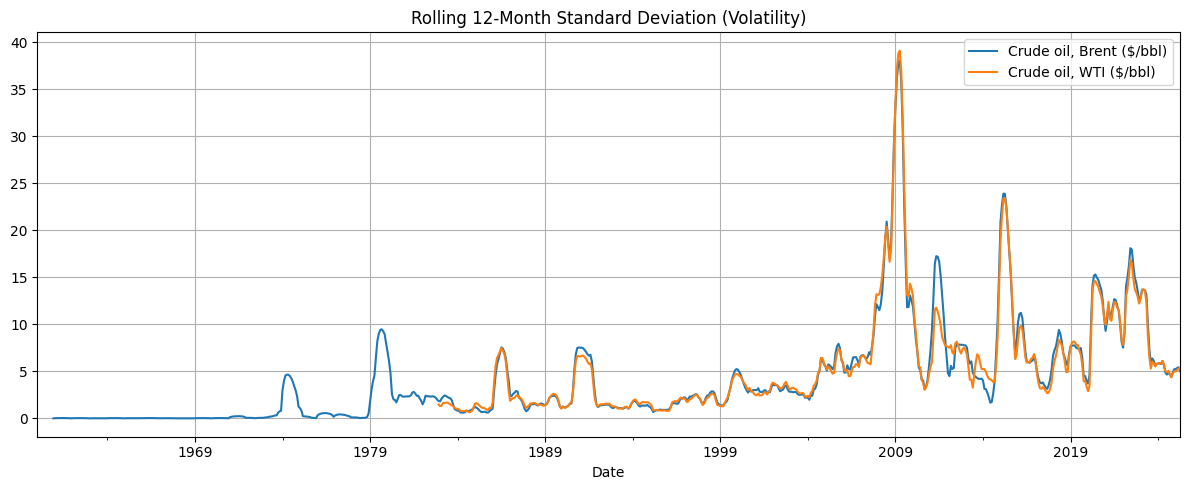

In [11]:
# Visualize volatility over time via 12-month rolling standard deviation for Brent and WTI
# Assesses the stability of crude oil prices and helps identify periods of high market volatility.

df_selected[['Crude oil, Brent ($/bbl)', 'Crude oil, WTI ($/bbl)']].rolling(12).std().plot(figsize=(12, 5))
plt.title("Rolling 12-Month Standard Deviation (Volatility)"); plt.grid(True)
plt.tight_layout(); plt.savefig("plots/rolling_volatility.png"); plt.show()

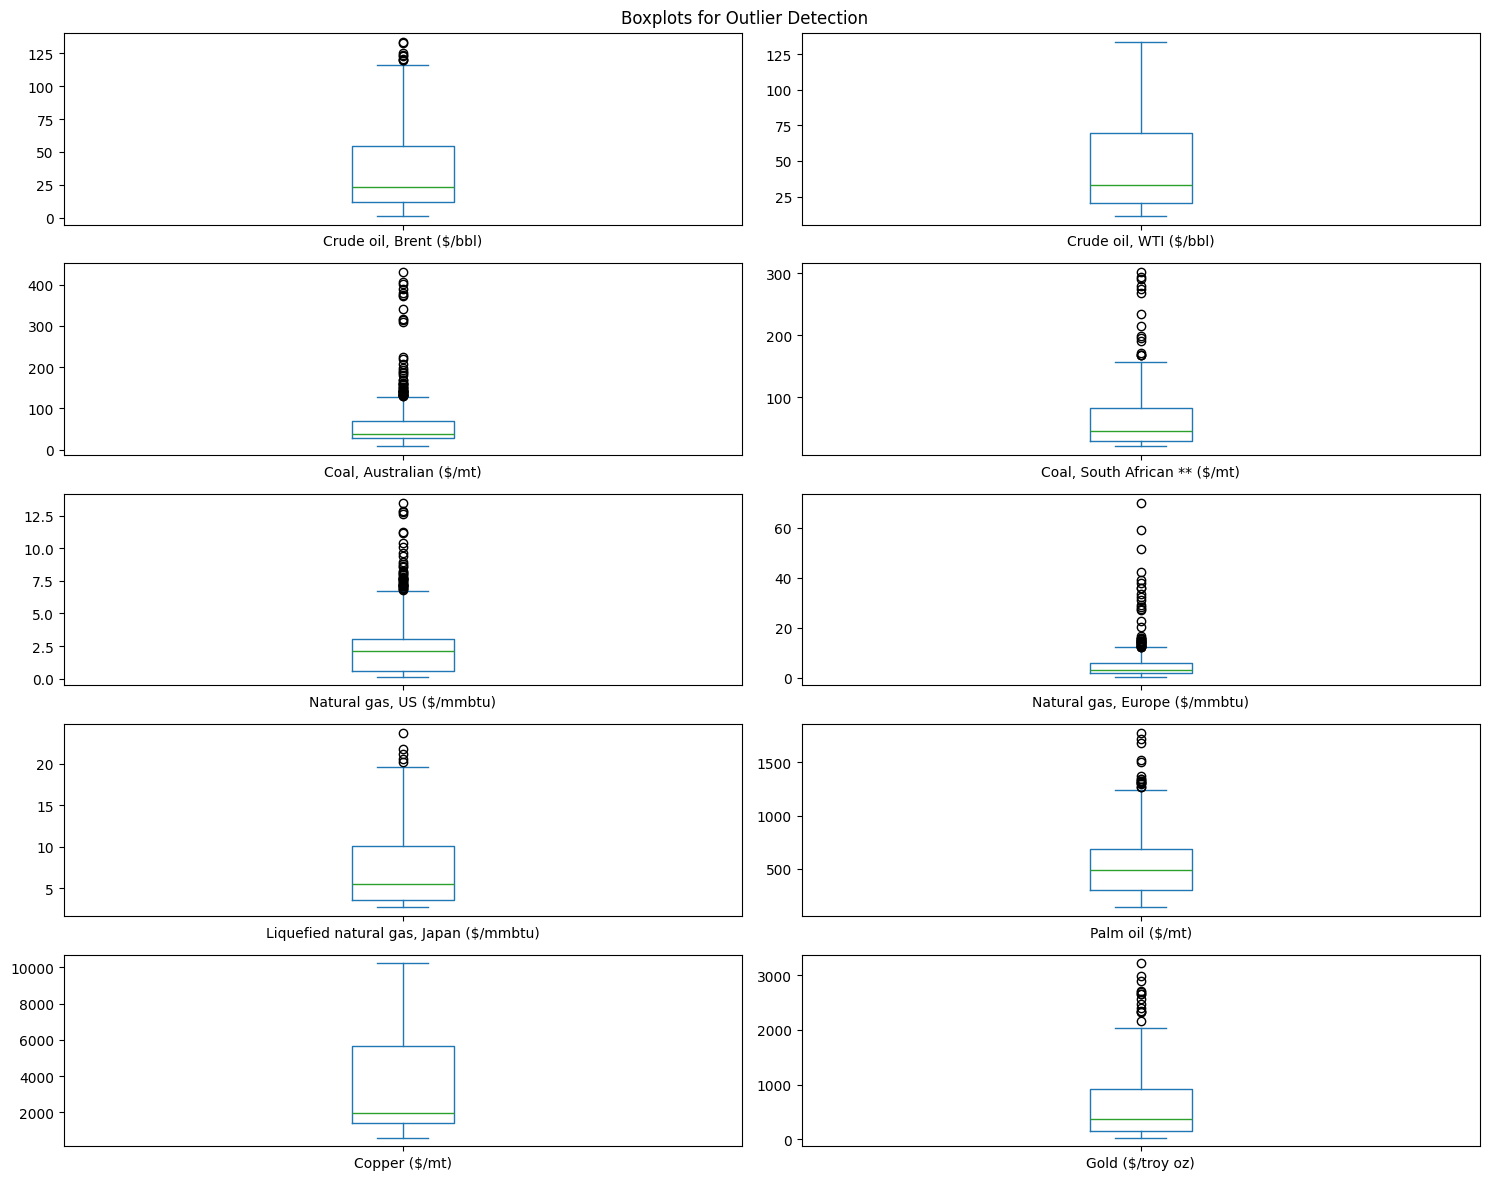

In [12]:
# Generate boxplots for each individual time series
# Boxplots (subplot layout) detect extreme values in each variable — assists in identifying outliers for winsorization or removal.

df_selected.plot(kind='box', subplots=True, layout=(5, 2), figsize=(15, 12), sharex=False, sharey=False)
plt.suptitle("Boxplots for Outlier Detection"); plt.tight_layout()
plt.savefig("plots/outlier_boxplots.png"); plt.show()

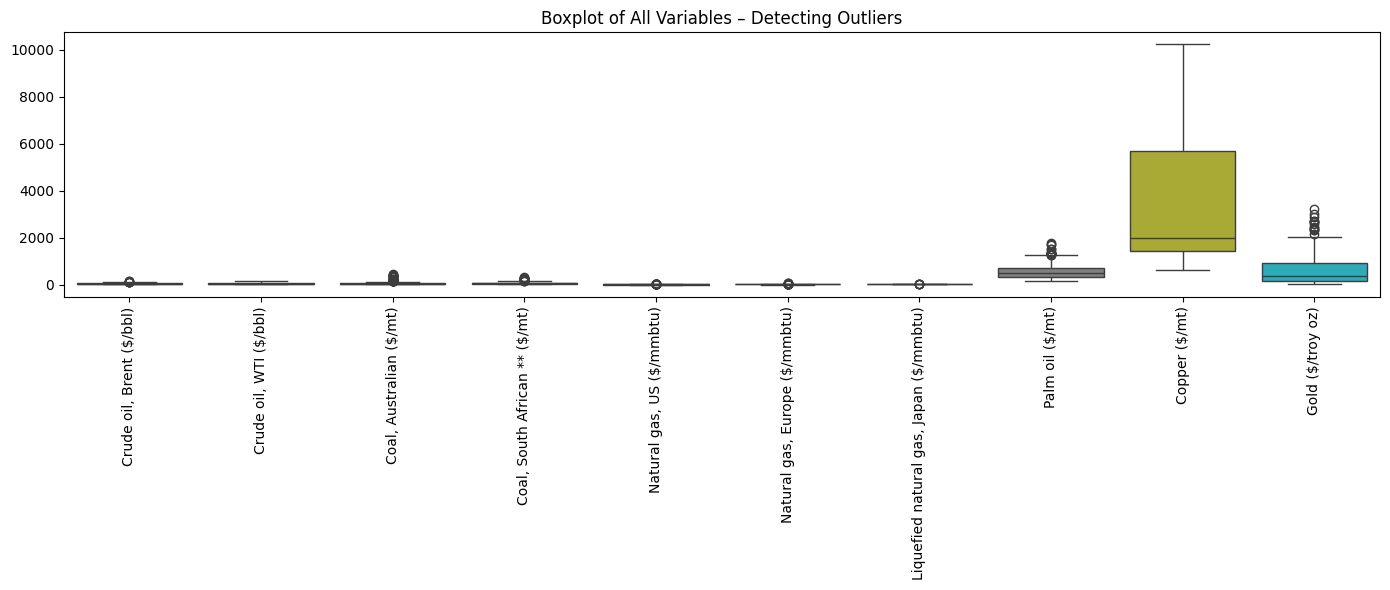

In [13]:
# Combined boxplot for a single visual summary
# Another way to visualize outliers for all variables side-by-side, with rotated labels for readability.

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_selected)
plt.xticks(rotation=90)
plt.title("Boxplot of All Variables – Detecting Outliers")
plt.tight_layout()
plt.savefig("plots/boxplots.png"); plt.show()

In [14]:
# Trim data to the period with valid WTI values (to align Brent and WTI series)
first_valid_wti = df_selected['Crude oil, WTI ($/bbl)'].first_valid_index()

# Filter data from the first valid WTI record onward and forward-fill missing values
df_trimmed = df_selected.loc[first_valid_wti:].copy().ffill()

# Ensure all remaining missing values are filled both forward and backward
# Prepares a clean and aligned dataset with no missing values — essential for time series modeling. Ensures Brent and WTI are in sync.
df_final = df_trimmed.ffill().bfill()

# ==============================================
## 7. Methodology: Data Preparation
## Includes winsorization, stationarity and normality tests, autocorrelation, and feature scaling.
# ==============================================

this block prepares the dataset for modeling by handling outliers, assessing assumptions, and scaling features

In [15]:
# Winsorization mitigates the impact of extreme outliers, improving model robustness while preserving data structure.

# Apply winsorization to cap the top and bottom 1% of values for each feature
df_winsor = df_final.apply(lambda x: winsorize(x, limits=[0.01, 0.01]))

# Augmented Dickey-Fuller test for stationarity on each feature
# Stores the p-value indicating whether we reject the null hypothesis (non-stationarity)
adf_results = {col: adfuller(df_winsor[col])[1] for col in df_winsor.columns}

# Shapiro-Wilk test for normality on each feature
# p-value > 0.05 suggests normal distribution
shapiro_results = {col: shapiro(df_winsor[col])[1] for col in df_winsor.columns}

# Calculate Durbin-Watson statistic for each series
# Values close to 2 suggest no autocorrelation; < 2: positive autocorrelation, > 2: negative autocorrelation
dw_stats = durbin_watson(df_winsor)

In [ ]:
# Select the optimal lag order for VAR model using Akaike Information Criterion (AIC)
# Chooses the number of lags (up to 12 months) to use in the Vector Autoregression based on AIC — lower is better.
# Select the optimal lag order for VAR model using Akaike Information Criterion (AIC)
# Chooses the number of lags (up to 12 months) to use in the Vector Autoregression based on AIC — lower is better.
lag_model = VAR(df_winsor)
lag_order_results = lag_model.select_order(maxlags=12)
# Print the full result (AIC, BIC, FPE, HQIC)
print(lag_order_results.summary())

selected_lag = lag_order_results.aic
print(f"Optimal lag (AIC): {selected_lag}")

# Scale features between 0 and 1 using MinMaxScaler to normalize input for LSTM and XGBoost
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_winsor),
    columns=df_winsor.columns,
    index=df_winsor.index
)

/home/mehreen/anaconda3/envs/newenv/lib/python3.9/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/home/mehreen/anaconda3/envs/newenv/lib/python3.9/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [17]:
# Save ADF results to CSV
pd.DataFrame.from_dict(adf_results, orient='index', columns=['ADF p-value']).to_csv("tables/adf_results.csv")

# Save Shapiro-Wilk normality test results to CSV
pd.DataFrame.from_dict(shapiro_results, orient='index', columns=['Shapiro p-value']).to_csv("tables/shapiro_results.csv")

# Save Durbin-Watson statistics to CSV
pd.Series(dw_stats, index=df_winsor.columns).to_csv("tables/durbin_watson_stats.csv")

# ==============================================
## 8. Model Development – VARMAX
# ==============================================

In [18]:
# First-order differencing to ensure stationarity (removes trends)
df_diff = df_final.diff().dropna()

# Define endogenous variables (targets): Brent and WTI crude oil prices
endog = df_diff[['Crude oil, Brent ($/bbl)', 'Crude oil, WTI ($/bbl)']]

# Define exogenous variables: remaining features (e.g., gold, coal, gas, etc.)
exog = df_diff.drop(columns=endog.columns)

# Split the data into training (until 2015-12) and testing (from 2016-01 onwards)
endog_train, endog_test = endog[:'2015-12'], endog['2016-01':]
exog_train, exog_test = exog[:'2015-12'], exog['2016-01':]



In [ ]:
# Initialize and fit the VARMAX model with lag order (p=1, q=0)
model = VARMAX(endog_train, exog=exog_train, order=(12, 0))
results = model.fit()

# Forecast
forecast_df = results.forecast(steps=len(endog_test), exog=exog_test)

# Use only the target forecasted differences
forecast_diff = forecast_df[['Crude oil, Brent ($/bbl)', 'Crude oil, WTI ($/bbl)']].copy()

# Get the last actual value from Dec 2015
last_actual = df_final.loc['2015-12', ['Crude oil, Brent ($/bbl)', 'Crude oil, WTI ($/bbl)']]

/home/mehreen/anaconda3/envs/newenv/lib/python3.9/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           25     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  4.35337D+00    |proj g|=  5.36047D+00

At iterate    5    f=  4.35056D+00    |proj g|=  3.28232D-01

At iterate   10    f=  4.35029D+00    |proj g|=  4.24484D-02

At iterate   15    f=  4.35010D+00    |proj g|=  1.56176D-01

At iterate   20    f=  4.34982D+00    |proj g|=  1.84878D+00

At iterate   25    f=  4.34934D+00    |proj g|=  6.40644D-01

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
   25     29     50      1     0     0   


   evaluations in the last line search.  Termination
   may possibly be caused by a bad search direction.


In [20]:
# Initialize DataFrame to store reconstructed values
reconstructed_forecast = pd.DataFrame(index=forecast_diff.index, columns=forecast_diff.columns)
reconstructed_forecast.iloc[0] = last_actual + forecast_diff.iloc[0]

# Iteratively reconstruct the original scale forecast
for i in range(1, len(forecast_diff)):
    reconstructed_forecast.iloc[i] = reconstructed_forecast.iloc[i-1] + forecast_diff.iloc[i]

# Get the actual values for comparison
actual_original = df_final.loc[forecast_diff.index, ['Crude oil, Brent ($/bbl)', 'Crude oil, WTI ($/bbl)']]

# Store the reconstructed forecast for future reference
forecast_varmax = reconstructed_forecast.copy()
forecast_varmax.to_csv("tables/forecast_varmax.csv")

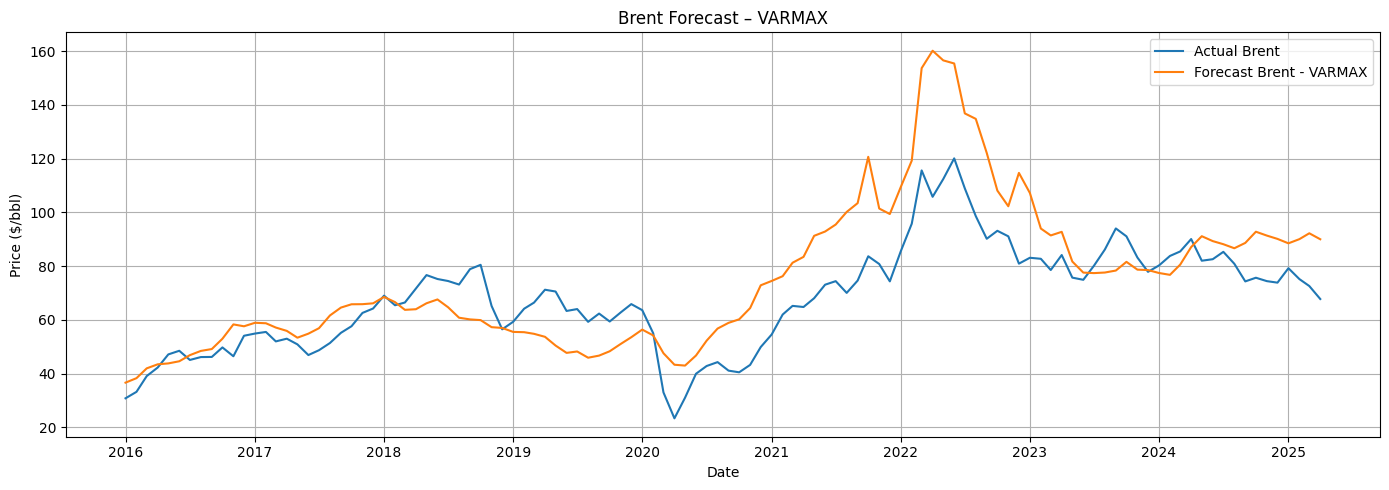

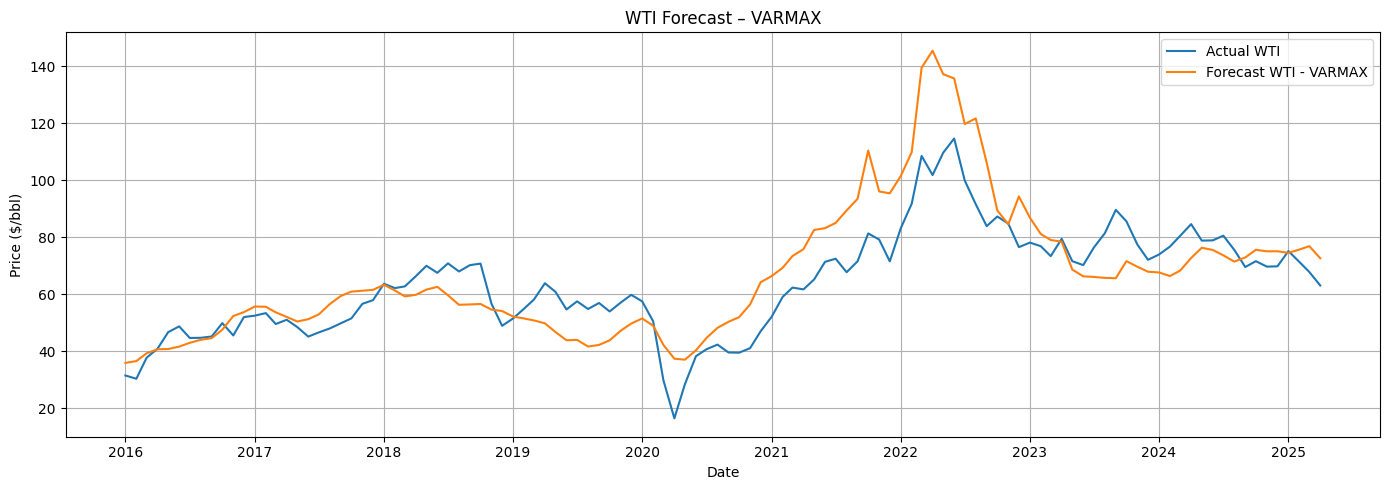

In [21]:
# Plot actual vs forecasted Brent crude oil prices
plt.figure(figsize=(14, 5))
plt.plot(df_final.loc[forecast_varmax.index, 'Crude oil, Brent ($/bbl)'], label='Actual Brent')
plt.plot(forecast_varmax['Crude oil, Brent ($/bbl)'], label='Forecast Brent - VARMAX')
plt.title("Brent Forecast – VARMAX")
plt.xlabel("Date"); plt.ylabel("Price ($/bbl)"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.savefig("plots/varmax_forecast_brent.png"); plt.show()

# Plot actual vs forecasted WTI crude oil prices
plt.figure(figsize=(14, 5))
plt.plot(df_final.loc[forecast_varmax.index, 'Crude oil, WTI ($/bbl)'], label='Actual WTI')
plt.plot(forecast_varmax['Crude oil, WTI ($/bbl)'], label='Forecast WTI - VARMAX')
plt.title("WTI Forecast – VARMAX")
plt.xlabel("Date"); plt.ylabel("Price ($/bbl)"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.savefig("plots/varmax_forecast_wti.png"); plt.show()

In [22]:
# Combine actual and forecasted values into a single table for reporting
comparison = pd.concat([
    df_final.loc[forecast_varmax.index, ['Crude oil, Brent ($/bbl)', 'Crude oil, WTI ($/bbl)']],
    forecast_varmax
], axis=1)

# Rename columns for clarity
comparison.columns = ['Actual Brent', 'Actual WTI', 'Forecast Brent', 'Forecast WTI']

# Save to CSV
comparison.to_csv("tables/comparison_varmax.csv")

# ==============================================
## 8. Model Development – XGBoost
# ==============================================


In [23]:
# Create a copy of the cleaned, aligned dataset
df_lagged = df_final.copy()

# Define the target variables: Brent and WTI prices
target_vars = ['Crude oil, Brent ($/bbl)', 'Crude oil, WTI ($/bbl)']

# Define feature variables: all other commodities (non-targets)
feature_vars = df_lagged.columns.difference(target_vars)

# Shift all feature variables by one time step (t-1) to avoid data leakage from future values
df_lagged[feature_vars] = df_lagged[feature_vars].shift(1)

# Remove rows that contain NaNs introduced by lagging
df_lagged.dropna(inplace=True)

# Split the lagged dataset into training (up to 2015-12) and testing sets (from 2016-01)
train = df_lagged[:'2015-12']
test = df_lagged['2016-01':]

In [24]:
# Extract predictor variables (X) and target variables (y) for Brent and WTI
X_train = train[feature_vars]
y_train_brent = train['Crude oil, Brent ($/bbl)']
y_train_wti = train['Crude oil, WTI ($/bbl)']

X_test = test[feature_vars]
y_test_brent = test['Crude oil, Brent ($/bbl)']
y_test_wti = test['Crude oil, WTI ($/bbl)']

In [25]:
# Train the XGBoost regressor for Brent price prediction
model_brent = XGBRegressor(objective='reg:squarederror')
model_brent.fit(X_train, y_train_brent)
y_pred_brent = model_brent.predict(X_test)

In [26]:
# Train the XGBoost regressor for WTI price prediction
model_wti = XGBRegressor(objective='reg:squarederror')
model_wti.fit(X_train, y_train_wti)
y_pred_wti = model_wti.predict(X_test)

# ==============================================
## 8. Model Development – LSTM (Multivariate)
# ==============================================


In [27]:
# Define input features and target columns
input_features = ['Crude oil, Brent ($/bbl)', 'Crude oil, WTI ($/bbl)']
target_brent = 'Crude oil, Brent ($/bbl)'
target_wti = 'Crude oil, WTI ($/bbl)'

# Step 1: Scale features using MinMaxScaler for LSTM input normalization
# LSTM models perform better when input values are on a consistent scale (0–1)
scaler = MinMaxScaler()
scaled_inputs = scaler.fit_transform(df_final[input_features])
scaled_df = pd.DataFrame(scaled_inputs, columns=input_features, index=df_final.index)

# Reattach unscaled target values for comparison and evaluation later
scaled_df[target_brent] = df_final[target_brent].values
scaled_df[target_wti] = df_final[target_wti].values

In [28]:
# Step 2: Create sequences of lagged observations for LSTM input
def create_sequences_multivariate(df, feature_cols, target_col, n_lags):
    X, y = [], []
    for i in range(n_lags, len(df)):
        X.append(df[feature_cols].iloc[i - n_lags:i].values)  # Input sequence (lagged features)
        y.append(df[target_col].iloc[i])                       # Target value at current timestep
    return np.array(X), np.array(y)

In [29]:
# Set number of timesteps (lags) to include in each input sequence
n_lags = 15

# Define train-test split date
split_date = '2016-01-01'
split_idx = scaled_df.index.get_loc(split_date)

# Create input/output sequences for both Brent and WTI
X_brent, y_brent = create_sequences_multivariate(scaled_df, input_features, target_brent, n_lags)
X_wti, y_wti = create_sequences_multivariate(scaled_df, input_features, target_wti, n_lags)

In [30]:
# Split sequences into training and testing sets based on split date
Xb_train, Xb_test = X_brent[:split_idx - n_lags], X_brent[split_idx - n_lags:]
yb_train, yb_test = y_brent[:split_idx - n_lags], y_brent[split_idx - n_lags:]
Xw_train, Xw_test = X_wti[:split_idx - n_lags], X_wti[split_idx - n_lags:]
yw_train, yw_test = y_wti[:split_idx - n_lags], y_wti[split_idx - n_lags:]

In [31]:
# Split further into training and validation sets (85% train / 15% val)
val_idx_b = int(len(Xb_train) * 0.85)
val_idx_w = int(len(Xw_train) * 0.85)
Xb_train_, Xb_val = Xb_train[:val_idx_b], Xb_train[val_idx_b:]
yb_train_, yb_val = yb_train[:val_idx_b], yb_train[val_idx_b:]
Xw_train_, Xw_val = Xw_train[:val_idx_w], Xw_train[val_idx_w:]
yw_train_, yw_val = yw_train[:val_idx_w], yw_train[val_idx_w:]

In [32]:
# Build LSTM model for Brent crude forecasting
model_b = Sequential([
    LSTM(64, input_shape=(n_lags, len(input_features))),  # LSTM layer with 64 units
    Dense(32, activation='relu'),                         # Dense hidden layer
    Dense(1)                                               # Output layer (single value prediction)
])
model_b.compile(optimizer='adam', loss='mse')              # Compile with MSE loss
history_b = model_b.fit(Xb_train_, yb_train_,              # Train the model
                        validation_data=(Xb_val, yb_val),
                        epochs=50, batch_size=32, verbose=0)

I0000 00:00:1748417745.525974   29293 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9818 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:2b:00.0, compute capability: 8.6
/home/mehreen/anaconda3/envs/newenv/lib/python3.9/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
I0000 00:00:1748417746.878068   29411 cuda_dnn.cc:529] Loaded cuDNN version 90501


In [33]:
# Build LSTM model for WTI crude forecasting (same structure as Brent)
model_w = Sequential([
    LSTM(64, input_shape=(n_lags, len(input_features))),
    Dense(32, activation='relu'),
    Dense(1)
])
model_w.compile(optimizer='adam', loss='mse')
history_w = model_w.fit(Xw_train_, yw_train_,
                        validation_data=(Xw_val, yw_val),
                        epochs=50, batch_size=32, verbose=0)

In [34]:
# Generate predictions for test set
brent_pred = model_b.predict(Xb_test)
wti_pred = model_w.predict(Xw_test)

# Align predictions with actual dates for time series plotting
forecast_index = df_final.index[-len(yb_test):]
brent_pred_series = pd.Series(brent_pred.ravel(), index=forecast_index)
wti_pred_series = pd.Series(wti_pred.ravel(), index=forecast_index)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


In [35]:
# Also align true target values for evaluation/visualization
yb_test_series = pd.Series(yb_test, index=forecast_index)
yw_test_series = pd.Series(yw_test, index=forecast_index)

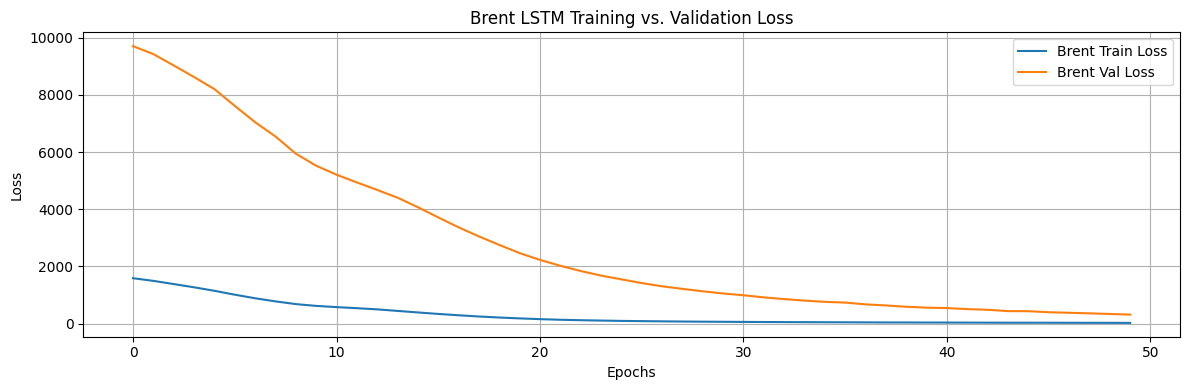

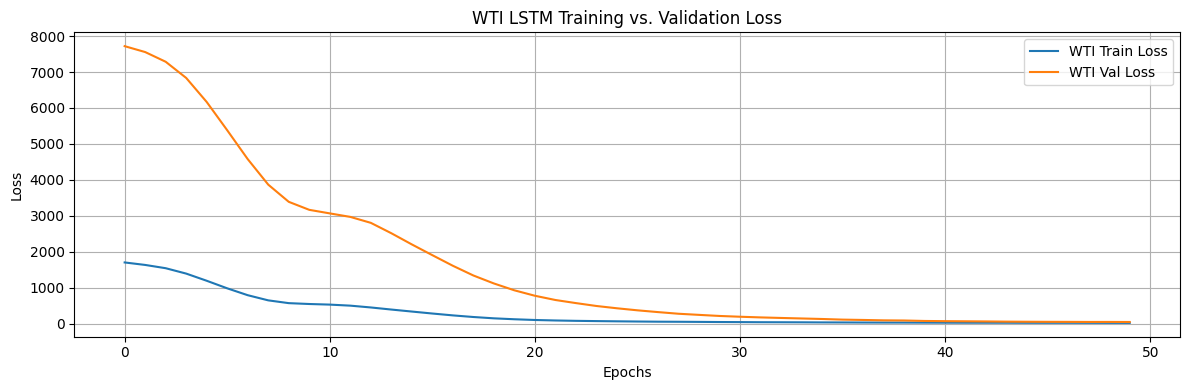

In [36]:
# Loss plots of Brent and WTI
plt.figure(figsize=(12, 4))
plt.plot(history_b.history['loss'], label='Brent Train Loss')
plt.plot(history_b.history['val_loss'], label='Brent Val Loss')
plt.title("Brent LSTM Training vs. Validation Loss")
plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.savefig("plots/lstm_train_val_loss_brent.png"); plt.show(); plt.close()

plt.figure(figsize=(12, 4))
plt.plot(history_w.history['loss'], label='WTI Train Loss')
plt.plot(history_w.history['val_loss'], label='WTI Val Loss')
plt.title("WTI LSTM Training vs. Validation Loss")
plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.savefig("plots/lstm_train_val_loss_wti.png"); plt.show(); plt.close()

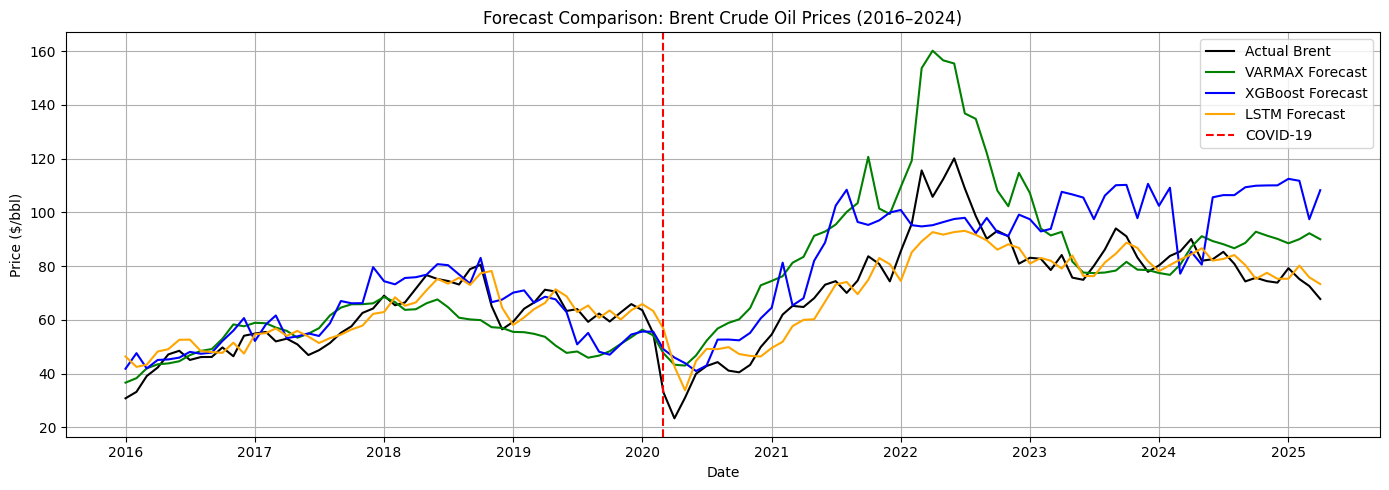

In [37]:
# ========================
# Brent Forecast Comparison
# ========================

forecast_index = y_test_brent.index

lstm_pred_series_brent = pd.Series(brent_pred.ravel(), index=forecast_index, name="LSTM")
xgb_pred_series_brent = pd.Series(y_pred_brent, index=forecast_index, name="XGBoost")
var_pred_series_brent = reconstructed_forecast['Crude oil, Brent ($/bbl)'].loc[forecast_index]

plt.figure(figsize=(14, 5))
plt.plot(y_test_brent, label="Actual Brent", color='black')
plt.plot(var_pred_series_brent, label="VARMAX Forecast", color='green')
plt.plot(xgb_pred_series_brent, label="XGBoost Forecast", color='blue')
plt.plot(lstm_pred_series_brent, label="LSTM Forecast", color='orange')
plt.axvline(pd.to_datetime("2020-03-01"), color='red', linestyle='--', label='COVID-19')
plt.title("Forecast Comparison: Brent Crude Oil Prices (2016–2024)")
plt.xlabel("Date")
plt.ylabel("Price ($/bbl)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("plots/forecast_comparison_brent_all_models.png")
plt.show()
plt.close()

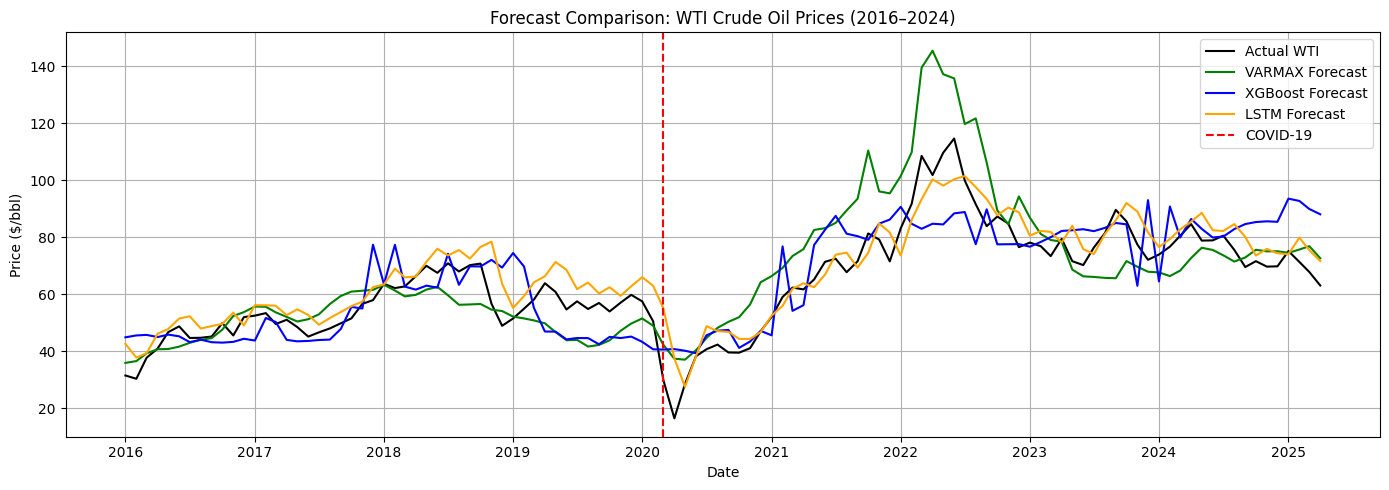

In [38]:
# ========================
# WTI Forecast Comparison
# ========================

forecast_index = y_test_wti.index

lstm_pred_series_wti = pd.Series(wti_pred.ravel(), index=forecast_index, name="LSTM")
xgb_pred_series_wti = pd.Series(y_pred_wti, index=forecast_index, name="XGBoost")
var_pred_series_wti = reconstructed_forecast['Crude oil, WTI ($/bbl)'].loc[forecast_index]

plt.figure(figsize=(14, 5))
plt.plot(y_test_wti, label="Actual WTI", color='black')
plt.plot(var_pred_series_wti, label="VARMAX Forecast", color='green')
plt.plot(xgb_pred_series_wti, label="XGBoost Forecast", color='blue')
plt.plot(lstm_pred_series_wti, label="LSTM Forecast", color='orange')
plt.axvline(pd.to_datetime("2020-03-01"), color='red', linestyle='--', label='COVID-19')
plt.title("Forecast Comparison: WTI Crude Oil Prices (2016–2024)")
plt.xlabel("Date")
plt.ylabel("Price ($/bbl)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("plots/forecast_comparison_wti_all_models.png")
plt.show()
plt.close()

In [39]:
"""
==============================================
9. Evaluation Design
Performance metrics and comparisons across models
==============================================
"""

def evaluate_forecast(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        'RMSE': np.sqrt(mse),
        'MSE': mse,
        'MAE': mean_absolute_error(y_true, y_pred),
        'MAPE': np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    }

In [40]:
# ========================
# Evaluation – Brent
# ========================
eval_results_brent = {
    'VARMAX': evaluate_forecast(
        df_final.loc[forecast_varmax.index, 'Crude oil, Brent ($/bbl)'],
        forecast_varmax['Crude oil, Brent ($/bbl)']
    ),
    'XGBoost': evaluate_forecast(y_test_brent, y_pred_brent),
    'LSTM': evaluate_forecast(yb_test, brent_pred.ravel())
}
eval_df_brent = pd.DataFrame(eval_results_brent).T
eval_df_brent.to_csv("tables/evaluation_results_brent.csv")

In [41]:
# ========================
# Evaluation – WTI
# ========================
eval_results_wti = {
    'VARMAX': evaluate_forecast(
        df_final.loc[forecast_varmax.index, 'Crude oil, WTI ($/bbl)'],
        forecast_varmax['Crude oil, WTI ($/bbl)']
    ),
    'XGBoost': evaluate_forecast(y_test_wti, y_pred_wti),
    'LSTM': evaluate_forecast(yw_test, wti_pred.ravel())
}
eval_df_wti = pd.DataFrame(eval_results_wti).T
eval_df_wti.to_csv("tables/evaluation_results_wti.csv")

In [42]:
"""
==============================================
10. Evaluation & Diagnostics
==============================================
"""

# 8.1 Evaluation Metrics
def evaluate_forecast(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"RMSE": rmse, "MSE": mse, "MAE": mae, "MAPE": mape}

In [43]:
# 8.2 Residual Diagnostics
def breusch_pagan_test(residuals):
    dummy_X = sm.add_constant(np.random.normal(size=(len(residuals), 2)))
    return het_breuschpagan(residuals, dummy_X)

In [44]:
# 8.3 SHAP Analysis
def run_shap_analysis(model, data, label):
    explainer = shap.Explainer(model)
    shap_values = explainer(data)
    shap.summary_plot(shap_values, data, feature_names=data.columns, show=False)
    plt.title(f"SHAP Summary - {label}")
    plt.tight_layout()
    plt.savefig(f"plots/shap_{label.lower()}.png")
    plt.show()

In [45]:
# 8.4 Year-wise Stability
def compute_yearly_rmse(y_true, y_pred):
    results = {}
    for year in range(2016, 2025):
        mask = y_true.index.year == year
        results[str(year)] = np.sqrt(mean_squared_error(y_true[mask], y_pred[mask]))
    return results
    
 

In [46]:
   
#  Brent XGBoost
metrics_xgb_brent = evaluate_forecast(y_test_brent, y_pred_brent)

# Brent VAR
metrics_var_brent = evaluate_forecast(y_test_brent, reconstructed_forecast['Crude oil, Brent ($/bbl)'])

# Brent LSTM
metrics_lstm_brent = evaluate_forecast(yb_test, brent_pred.ravel())

# Combine into one DataFrame
eval_df_brent = pd.DataFrame({
    'XGBoost': metrics_xgb_brent,
    'VAR': metrics_var_brent,
    'LSTM': metrics_lstm_brent
}).T

In [47]:
# Residuals (actual - forecast)
resid_var_brent = y_test_brent - reconstructed_forecast['Crude oil, Brent ($/bbl)']
resid_var_wti = y_test_wti - reconstructed_forecast['Crude oil, WTI ($/bbl)']

# Run Breusch-Pagan tests
bp_stat_brent = breusch_pagan_test(resid_var_brent)
bp_stat_wti = breusch_pagan_test(resid_var_wti)

# Combine results into one DataFrame
bp_df = pd.DataFrame(
    [bp_stat_brent, bp_stat_wti],
    index=['Brent', 'WTI'],
    columns=['LM stat', 'LM p-value', 'F stat', 'F p-value']
)

# Save to CSV
bp_df.to_csv("tables/breusch_pagan_combined.csv")

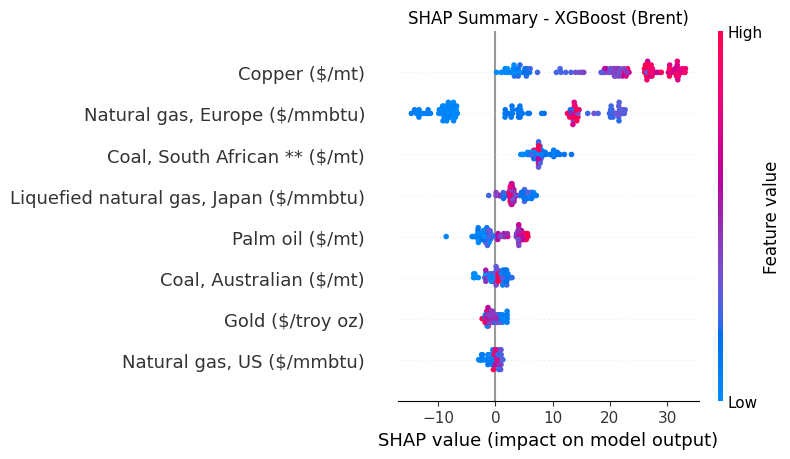

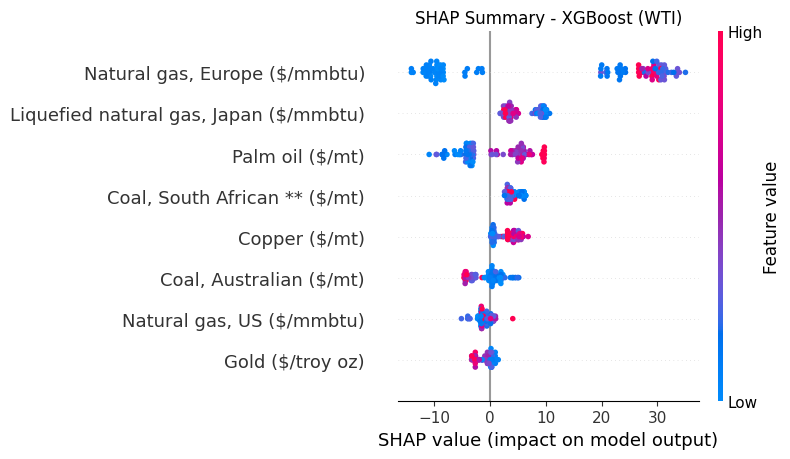

XGBoost Brent Yearly RMSE:
 {'2016': 6.502792555450511, '2017': 7.787405295921651, '2018': 5.9898548183677125, '2019': 9.089829668174739, '2020': 11.554675352637318, '2021': 19.83060052793473, '2022': 13.229706620964441, '2023': 21.617788787314144, '2024': 25.556821308402714}


In [48]:
# SHAP for Brent
run_shap_analysis(model_brent, test[feature_vars], label="XGBoost (Brent)")

# SHAP for WTI
run_shap_analysis(model_wti, test[feature_vars], label="XGBoost (WTI)")

# yearly rmse for analysis
xgb_yearly_rmse = compute_yearly_rmse(y_test_brent, pd.Series(y_pred_brent, index=y_test_brent.index))
print("XGBoost Brent Yearly RMSE:\n", xgb_yearly_rmse)

# Save Brent evaluation table
eval_df_brent.to_csv("tables/eval_metrics_brent.csv")


# Save yearly RMSE for Brent XGBoost
xgb_yearly_rmse_df = pd.DataFrame.from_dict(xgb_yearly_rmse, orient='index', columns=['Brent RMSE'])
xgb_yearly_rmse_df.to_csv("tables/yearly_rmse_xgb_brent.csv")

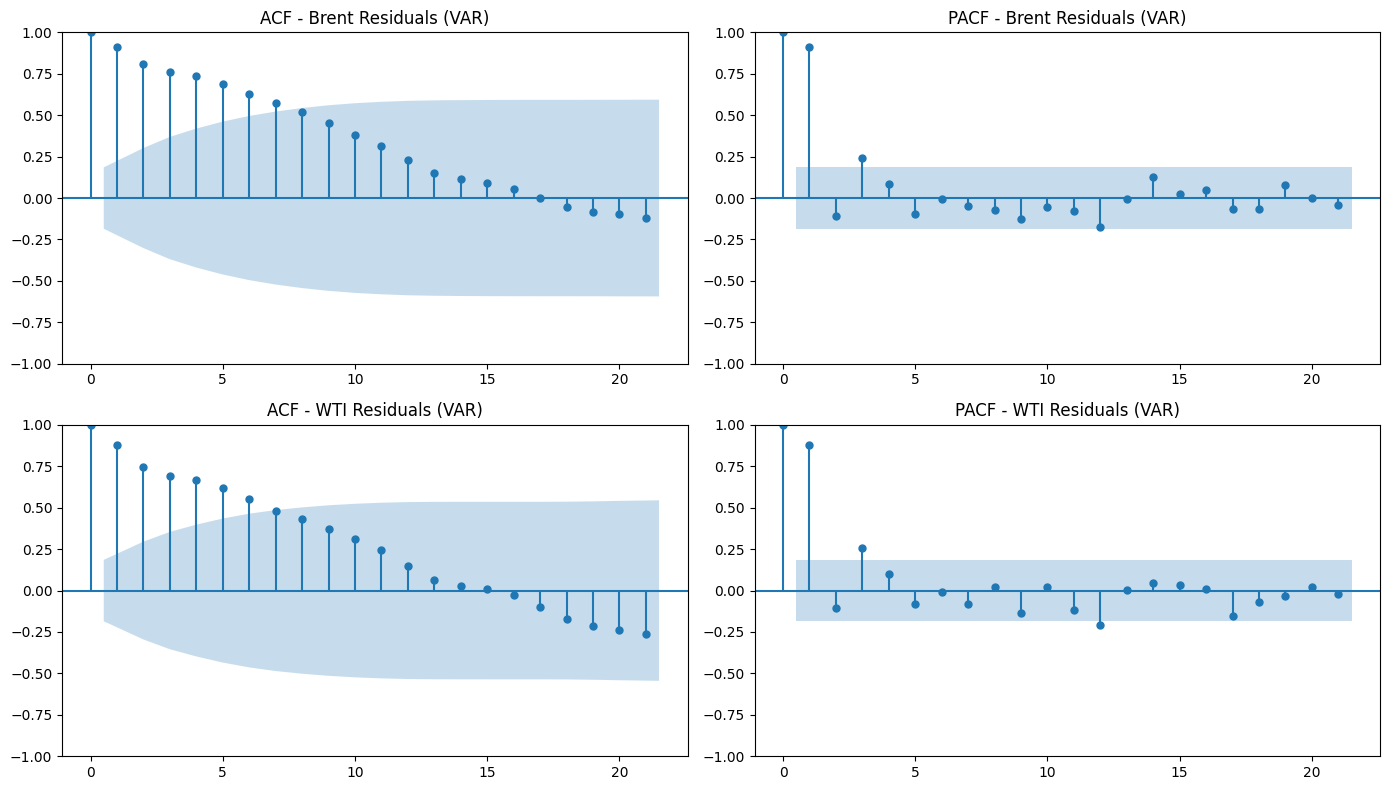

In [49]:
# === ACF/PACF Plots for Residuals (VAR) ===

resid_brent = y_test_brent - reconstructed_forecast['Crude oil, Brent ($/bbl)']
resid_wti = y_test_wti - reconstructed_forecast['Crude oil, WTI ($/bbl)']

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
plot_acf(resid_brent, ax=ax[0][0])
ax[0][0].set_title("ACF - Brent Residuals (VAR)")
plot_pacf(resid_brent, ax=ax[0][1])
ax[0][1].set_title("PACF - Brent Residuals (VAR)")
plot_acf(resid_wti, ax=ax[1][0])
ax[1][0].set_title("ACF - WTI Residuals (VAR)")
plot_pacf(resid_wti, ax=ax[1][1])
ax[1][1].set_title("PACF - WTI Residuals (VAR)")
plt.tight_layout()
plt.savefig("plots/acf_pacf_var_residuals.png")
plt.show()

In [50]:
# Load previously saved evaluation metrics
eval_brent = pd.read_csv("tables/evaluation_results_brent.csv", index_col=0)
eval_wti = pd.read_csv("tables/evaluation_results_wti.csv", index_col=0)
yearly_rmse_brent = pd.read_csv("tables/yearly_rmse_xgb_brent.csv")

# Combine Brent and WTI error metrics side-by-side
combined_metrics = pd.concat([
    eval_brent.add_suffix(" (Brent)"),
    eval_wti.add_suffix(" (WTI)")
], axis=1)

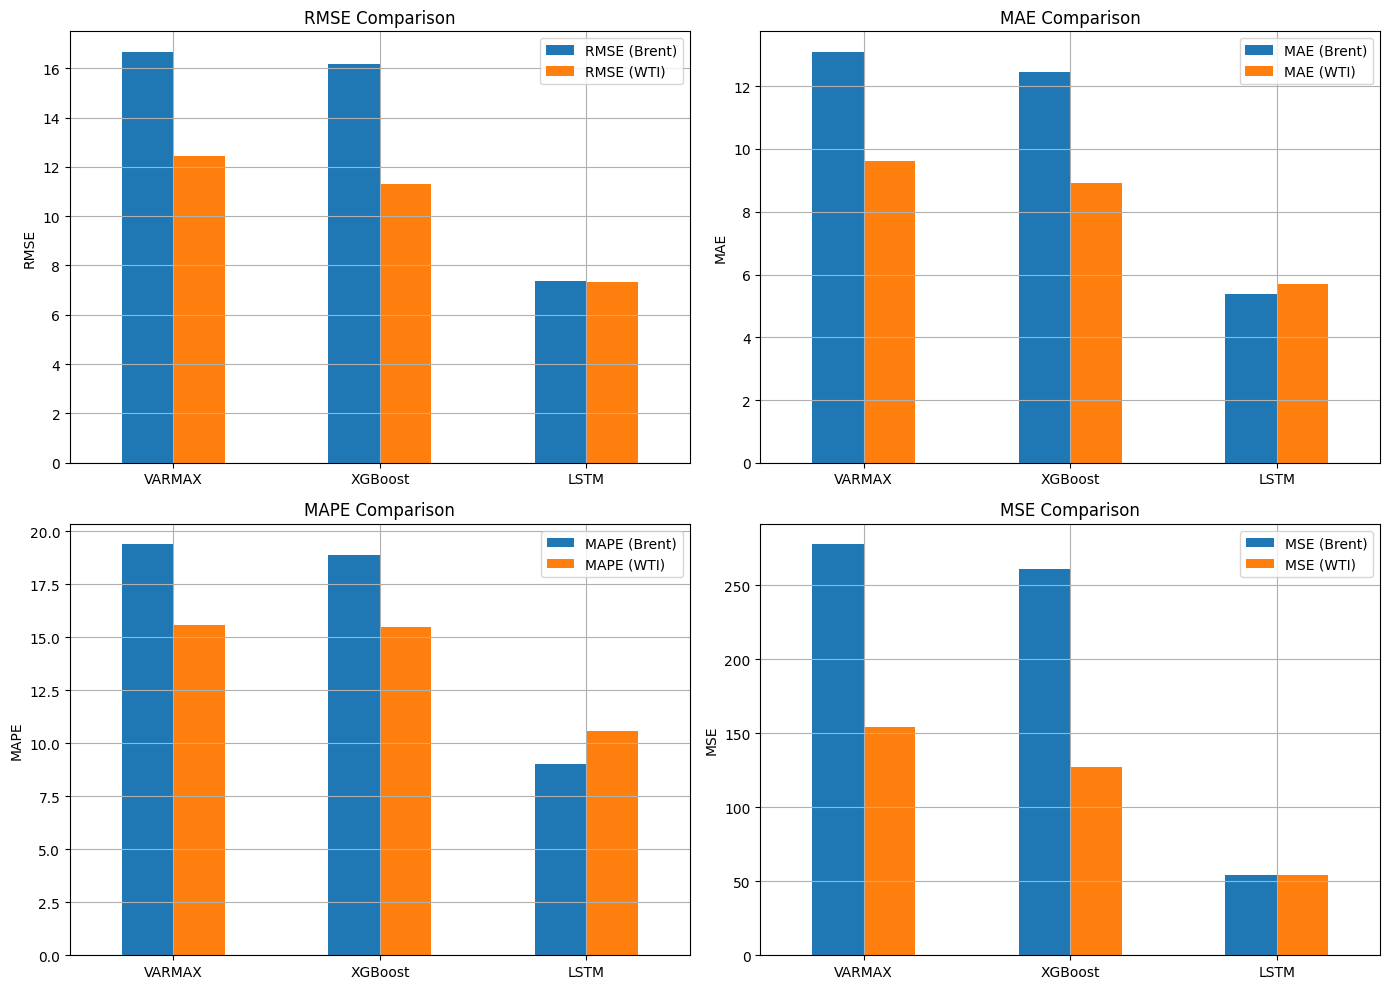

In [51]:
# Plotting comparison of error metrics for Brent and WTI
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = ['RMSE', 'MAE', 'MAPE', 'MSE']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for ax, metric in zip(axes.flat, metrics):
    combined_metrics[[f"{metric} (Brent)", f"{metric} (WTI)"]].plot.bar(ax=ax, color=colors[:2])
    ax.set_title(f"{metric} Comparison")
    ax.set_ylabel(metric)
    ax.grid(True)
    ax.set_xticklabels(combined_metrics.index, rotation=0)

plt.tight_layout()
plt.savefig("plots/combined_error_metrics_brent_wti.png")
plt.show()

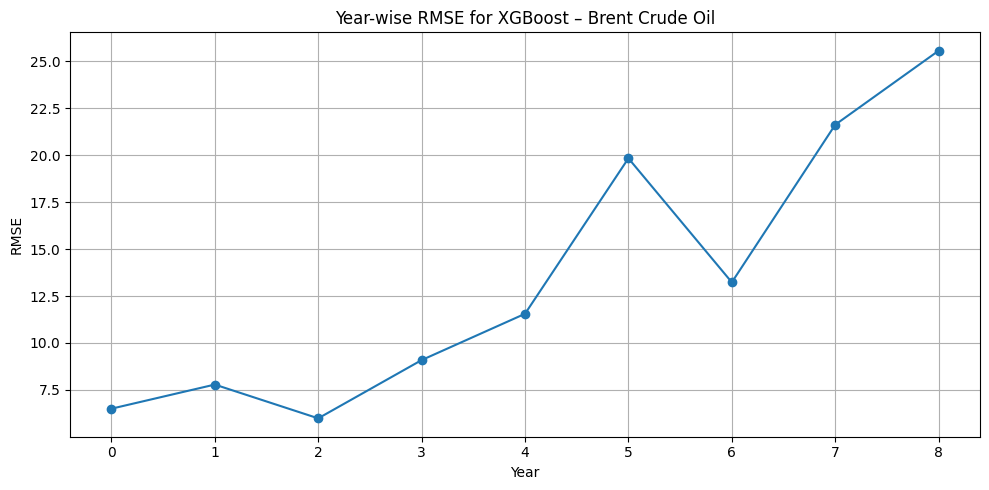

In [52]:
# Plot year-wise RMSE for Brent (XGBoost only)
plt.figure(figsize=(10, 5))
plt.plot(yearly_rmse_brent.index, yearly_rmse_brent['Brent RMSE'], marker='o', linestyle='-')
plt.title("Year-wise RMSE for XGBoost – Brent Crude Oil")
plt.xlabel("Year")
plt.ylabel("RMSE")
plt.grid(True)
plt.tight_layout()
plt.savefig("plots/yearly_rmse_xgb_brent.png")
plt.show()